# Clasificación de audio
Creación de un clasificador de audio. Para este caso en concreto un clasificador entre Maya, Nahuatl y Zapoteco

## Registro de la experimentación
Se guarda un registro de cada experimento en formato csv

In [1]:
import pandas as pd
CSV_LOG_PATH = '../resultados/log.csv'
try:
    df_log = pd.read_csv(CSV_LOG_PATH)
    if 'Audio_Folders_UsedNotes' in df_log.columns:
        df_log.rename(columns={'Audio_Folders_UsedNotes': 'Notes'}, inplace=True)
except FileNotFoundError:
    df_log = pd.DataFrame(columns=[
        'ID_Exp', 'Hash', 'Languages', 'Model', 'Audio_Length',
        'Image_Amount', 'Parameters', 'Results', 'Split_Seed',
        'hasSilence', 'Audio_Folders_Used', 'Notes'
    ])


## Configuración inicial: 
importe de paquetes, números "semillas" y demás constantes claves para la creación del clasificador

In [ ]:
import numpy as np
import os
import random
import hashlib
import math
import warnings
warnings.filterwarnings('ignore')

SEED = 18062026
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)

import librosa
import librosa.display
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, accuracy_score, recall_score,
    precision_score, f1_score, classification_report
)

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

%matplotlib inline

# ============ CONFIGURACIÓN ============
LANGUAGES = ['maya', 'nahuatl', 'zapoteco']
LANGUAGES.sort(key=str.lower)
NUM_CLASSES = len(LANGUAGES)
USED_MODEL = 'MobileNetV2'
AUDIO_LENGTH = 5 # segundos
SR = 16000  # sample rate
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
MAX_IMAGES_PER_CLASS = 1731
INITIAL_LR = 1e-3
FINE_TUNE_LR = 1e-5
SPLIT_SEED = 4
HAS_SILENCE = False
USE_CLEAN_FILTER = True
CLEAN_CSV_PATH = '../resultados/audio_quality.csv'
VAD_THRESHOLD = 0.15
RMS_THRESHOLD = 0.005

# Rutas
FIRST_FOLDER = '../datos/Audios v4/Maya'
SECOND_FOLDER = '../datos/Audios v4/Nahuatl'
THIRD_FOLDER = '../datos/Audios v4/Zapoteco'
FOLDER_PATH_LIST = [FIRST_FOLDER, SECOND_FOLDER, THIRD_FOLDER]
SPECTROGRAM_DIRS = [
    '../datos/spectrograms/Maya',
    '../datos/spectrograms/Nahuatl',
    '../datos/spectrograms/Zapoteco'
]

image_amount = {lang: MAX_IMAGES_PER_CLASS for lang in LANGUAGES}
parameters = {
    'batch_size': BATCH_SIZE,
    'frequency': SR,
    'learning_rate': INITIAL_LR
}
hash_input = hashlib.md5(
    f"{LANGUAGES},{USED_MODEL},{AUDIO_LENGTH},{image_amount}.{parameters},{SPLIT_SEED},{HAS_SILENCE}".encode()
).hexdigest()
print(f"Experiment hash: {hash_input}")

Experiment hash: 0ffe3bc40cbd3761561b16a6f8973b55


## Generación de espectrogramas a partir de audios WAV
Se puede omitir esta celda cuando ya están generados los espectrogramas que se van a usar

Establecer las rutas en el arreglo `WAV_SOURCE_DIRS` (relativas a `codigo/`) y al ejecutar la celda se generarán los espectrogramas en `../datos/spectrograms/`.

In [ ]:
def create_spectrogram(audio_file, image_file, sr=SR):
    fig = plt.figure()
    ax = fig.add_subplot(1, 1, 1)
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

    y, _ = librosa.load(audio_file, sr=sr)
    ms = librosa.feature.melspectrogram(y=y, sr=sr)
    log_ms = librosa.power_to_db(ms, ref=np.max)
    librosa.display.specshow(log_ms, sr=sr)

    fig.savefig(image_file)
    plt.close(fig)

# Utiliza el csv de audio_quality.csv para filtrar archivos de audio sospechosos de ruido
exclude_files = set()
if USE_CLEAN_FILTER and os.path.exists(CLEAN_CSV_PATH):
    import pandas as pd
    df_q = pd.read_csv(CLEAN_CSV_PATH)
    exclude_files = set(df_q[df_q['suspect_noise'] == True]['file'])
    print(f"Loaded {CLEAN_CSV_PATH}: excluding {len(exclude_files)} noise-suspect files")
elif USE_CLEAN_FILTER:
    print(f"Warning: {CLEAN_CSV_PATH} not found. Se necesita el reporte de calidad de audio.")

def create_pngs_from_wavs(input_path, output_path):
    os.makedirs(output_path, exist_ok=True)
    skipped = 0
    for fname in os.listdir(input_path):
        input_file = os.path.join(input_path, fname)
        if not os.path.isfile(input_file) or not fname.lower().endswith('.wav'):
            continue
        if fname in exclude_files:
            skipped += 1
            continue
        output_file = os.path.join(output_path, fname.replace('.wav', '.png'))
        create_spectrogram(input_file, output_file)
    if skipped:
        print(f"  Skipped {skipped} noise-suspect files in {os.path.basename(output_path)}")

WAV_SOURCE_DIRS = [
    ('../datos/Audios v4/Maya', '../datos/spectrograms/Maya'),
    ('../datos/Audios v4/Nahuatl', '../datos/spectrograms/Nahuatl'),
    ('../datos/Audios v4/Zapoteco', '../datos/spectrograms/Zapoteco'),
]

# Generar si los espectrogramas no existen
all_exist = all(
    os.path.exists(dst) and any(f.endswith('.png') for f in os.listdir(dst))
    for _, dst in WAV_SOURCE_DIRS
)

if not all_exist:
    print('Spectrogram PNGs not found. Generating from WAV files...')
    for src, dst in WAV_SOURCE_DIRS:
        print(f'  {src} -> {dst}')
        create_pngs_from_wavs(src, dst)
    print('Done generating spectrograms.')
else:
    print('Spectrogram PNGs already exist. Skipping generation.')

Loaded audio_quality.csv: excluding 930 noise-suspect files
Spectrogram PNGs not found. Generating from WAV files...
  Audios_Usar5s v2/Maya -> spectrograms/Maya
  Skipped 256 noise-suspect files in Maya
  Audios_Usar5s v2/Nahuatl -> spectrograms/Nahuatl
  Skipped 276 noise-suspect files in Nahuatl
  Audios_Usar5s v2/Zapoteco -> spectrograms/Zapoteco
  Skipped 303 noise-suspect files in Zapoteco
Done generating spectrograms.


## Carga de espectrogramas PNG

Se cargarán en memoria los espectrogramas generados anteriormente y se ordenarán de forma aleatoria.

In [3]:
from tensorflow.keras.preprocessing import image

def load_images_from_path(path, label, max_images=MAX_IMAGES_PER_CLASS, seed=SPLIT_SEED):
    files = np.array([f for f in os.listdir(path) if f.lower().endswith('.png')])
    rng = np.random.default_rng(seed)
    picks = rng.choice(files, size=min(max_images, len(files)), replace=False)

    images = []
    labels = []
    for fname in picks:
        img = image.load_img(os.path.join(path, fname), target_size=IMG_SIZE)
        images.append(image.img_to_array(img))
        labels.append(label)
    return images, labels

def show_images(images, n=8):
    fig, axes = plt.subplots(1, n, figsize=(20, 20),
                             subplot_kw={'xticks': [], 'yticks': []})
    for i, ax in enumerate(axes.flat):
        if i < len(images):
            ax.imshow(images[i].astype('uint8'))
    plt.show()

In [ ]:
# ============ CARGA DE DATOS ============
available_per_class = []
for _, spec_dir in zip(LANGUAGES, SPECTROGRAM_DIRS):
    count = len([f for f in os.listdir(spec_dir) if f.lower().endswith('.png')])
    available_per_class.append(count)
effective_max = min(available_per_class)
print(f"Images per class: {dict(zip(LANGUAGES, available_per_class))}")
print(f"Using effective_max = {effective_max} (min across classes)")

x, y = [], []
for idx, (lang, spec_dir) in enumerate(zip(LANGUAGES, SPECTROGRAM_DIRS)):
    images, labels = load_images_from_path(spec_dir, idx, max_images=effective_max)
    print(f"Loaded {len(images)} images for {lang} (label={idx})")
    x.extend(images)
    y.extend(labels)

# ============ CONFIGURACIÓN FINAL ============
MAX_IMAGES_PER_CLASS = effective_max
image_amount = {lang: effective_max for lang in LANGUAGES}

x = np.array(x)
y = np.array(y)
print(f"\nTotal: {len(x)} images, shape={x.shape}, labels={np.unique(y, return_counts=True)}")

Images per class: {'maya': 1809, 'nahuatl': 1604, 'zapoteco': 1428}
Using effective_max = 1428 (min across classes)
Loaded 1428 images for maya (label=0)
Loaded 1428 images for nahuatl (label=1)
Loaded 1428 images for zapoteco (label=2)

Total: 4284 images, shape=(4284, 224, 224, 3), labels=(array([0, 1, 2]), array([1428, 1428, 1428]))


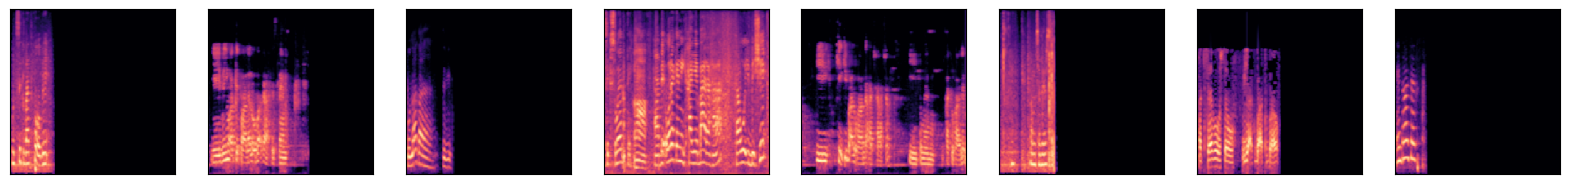

In [5]:
# Display sample images
show_images(x)

## Particionamiento de entrenamiento / validación / pruebas

In [6]:
x_train, x_val, y_train, y_val = train_test_split(
    x, y, stratify=y, test_size=0.20, random_state=SPLIT_SEED
)

print(f"Train: {len(x_train)} | Validation: {len(x_val)}")
print(f"Train class distribution: {np.bincount(y_train)}")
print(f"Val class distribution:   {np.bincount(y_val)}")

Train: 3427 | Validation: 857
Train class distribution: [1142 1143 1142]
Val class distribution:   [286 285 286]


In [ ]:
# ============ PREPROCESAMIENTO ============
from tensorflow.keras.utils import to_categorical

x_train_pp = np.array(x_train) / 255.0
x_val_pp = np.array(x_val) / 255.0
y_train_enc = to_categorical(y_train, num_classes=3)
y_val_enc = to_categorical(y_val, num_classes=3)
print(f"Preprocessing done: train={x_train_pp.shape}, val={x_val_pp.shape}")

Preprocessing done: train=(3427, 224, 224, 3), val=(857, 224, 224, 3)


## Aumento artificial de datos

Se realiza un aumento de datos solamente para la partición de entrenamiento, no para validación ni pruebas

In [ ]:
# Aumento de datos con SpecAugment: enmascaramiento de frecuencia y tiempo para espectrogramas
import tensorflow as tf

def spec_augment(image, freq_mask_param=8, time_mask_param=8):
    img = tf.cast(image, tf.float32)
    f, t, c = tf.shape(img)[0], tf.shape(img)[1], tf.shape(img)[2]
    # Frequency masking
    f_mask = tf.random.uniform((), maxval=freq_mask_param, dtype=tf.int32)
    f_start = tf.random.uniform((), maxval=f - f_mask, dtype=tf.int32)
    mask_f = tf.concat([
        tf.ones((f_start, t, c)),
        tf.zeros((f_mask, t, c)),
        tf.ones((f - f_start - f_mask, t, c))
    ], axis=0)
    img = img * mask_f
    # Time masking
    t_mask = tf.random.uniform((), maxval=time_mask_param, dtype=tf.int32)
    t_start = tf.random.uniform((), maxval=t - t_mask, dtype=tf.int32)
    mask_t = tf.concat([
        tf.ones((f, t_start, c)),
        tf.zeros((f, t_mask, c)),
        tf.ones((f, t - t_start - t_mask, c))
    ], axis=1)
    img = img * mask_t
    return img

def aug_gen(x, y, batch_size):
    idxs = np.arange(len(x))
    while True:
        np.random.shuffle(idxs)
        for start in range(0, len(idxs), batch_size):
            batch_idxs = idxs[start:start+batch_size]
            batch_x = x[batch_idxs].copy()
            for i in range(len(batch_x)):
                batch_x[i] = spec_augment(batch_x[i]).numpy()
            yield batch_x, y[batch_idxs]

train_generator = aug_gen(x_train_pp, y_train_enc, BATCH_SIZE)
STEPS_PER_EPOCH = int(math.ceil(len(x_train_pp) / BATCH_SIZE))


## Construcción del modelo alternativo: CNN sencillo

Si se va a entrenar con MobileNetV2 saltar esta celda, de lo contrario ejecutarla y saltar las siguientes 3

In [ ]:
def build_lightweight_cnn(input_shape=(*IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """Creación de un modelo CNN ligero desde cero (sin transferencia de aprendizaje)."""
    from tensorflow.keras.layers import (
        Conv2D, MaxPooling2D, GlobalAveragePooling2D,
        Dense, Dropout, BatchNormalization, Input
    )
    from tensorflow.keras.regularizers import l2
    from tensorflow.keras.models import Model

    inp = Input(shape=input_shape)
    x = Conv2D(32, (3, 3), activation='relu', padding='same',
               kernel_regularizer=l2(1e-4))(inp)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    x = Conv2D(64, (3, 3), activation='relu', padding='same',
               kernel_regularizer=l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    x = Conv2D(128, (3, 3), activation='relu', padding='same',
               kernel_regularizer=l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    x = Conv2D(256, (3, 3), activation='relu', padding='same',
               kernel_regularizer=l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = GlobalAveragePooling2D()(x)

    x = Dense(64, activation='relu', kernel_regularizer=l2(1e-4))(x)
    x = Dropout(0.5)(x)
    out = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=inp, outputs=out)
    return model

#comentar o descomentar según se quiera usar MobileNetV2 o la CNN ligera
model = build_lightweight_cnn()
model.summary()

## Construcción del modelo: MobileNetV2 + GlobalAveragePooling

In [ ]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)
base_model.trainable = False  # congelamiento de la base para la Fase 1

# Build classifier on top
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu', kernel_regularizer=l2(5e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.6)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,851 (9.24 MB)

 Trainable params: 164,611 (643.01 KB)

 Non-trainable params: 2,258,240 (8.61 MB)

## Fase 1: Entrenar el clasificador

Solo las capas GAP, Dense y Dropout son entrenadar.

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=INITIAL_LR),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

callbacks = [
    # Calentamiento de la tasa de aprendizaje: comienza desde 0, aumenta linealmente hasta INITIAL_LR durante 3 épocas
    tf.keras.callbacks.LearningRateScheduler(
        lambda epoch, lr: INITIAL_LR * min(1.0, (epoch + 1) / 3.0)
    ),
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7)
]

hist1 = model.fit(
    train_generator,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=(x_val_pp, y_val_enc),
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.6262 - loss: 0.9253 - val_accuracy: 0.3326 - val_loss: 1.5955 - learning_rate: 3.3333e-04
Epoch 2/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.7064 - loss: 0.8053 - val_accuracy: 0.3326 - val_loss: 2.4218 - learning_rate: 6.6667e-04
Epoch 3/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.7847 - loss: 0.7090 - val_accuracy: 0.3326 - val_loss: 2.0889 - learning_rate: 0.0010
Epoch 4/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.8442 - loss: 0.6168 - val_accuracy: 0.5473 - val_loss: 1.1552 - learning_rate: 0.0010
Epoch 5/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.8897 - loss: 0.5616 - val_accuracy: 0.6138 - val_loss: 1.3121 - learning_rate: 0.0010
Epoch 6/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9171 - loss: 0.5238 - val_accuracy: 0.8145 - val_loss: 0.6852 - learning_rate: 0.0010
Epoch 7/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9405 - 

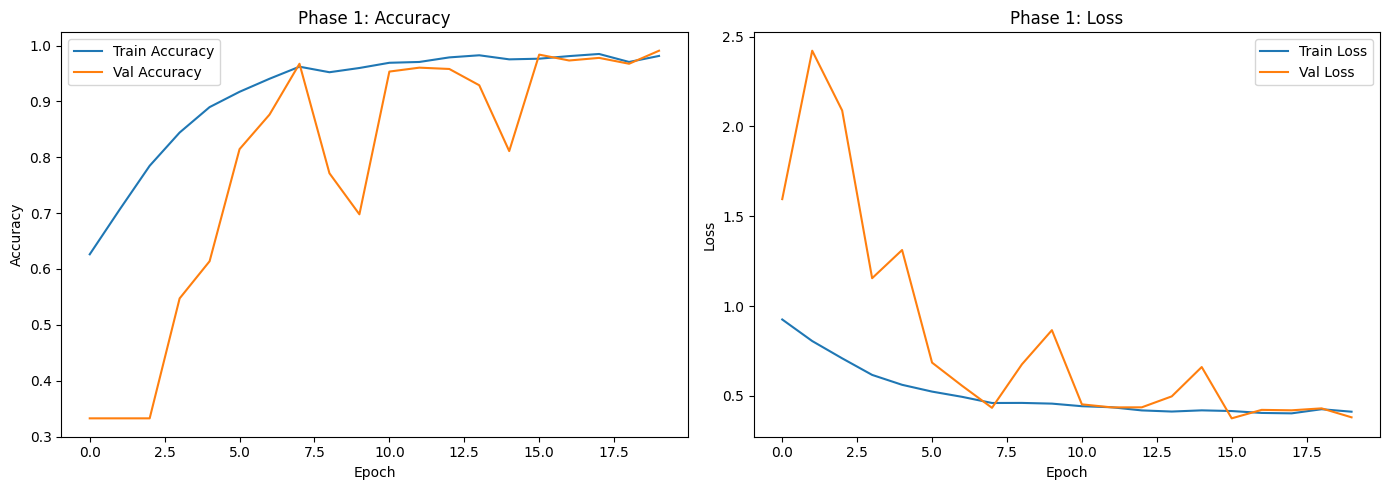

In [ ]:
# Grafica de las curvas de entrenamiento de la Fase 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(hist1.history['accuracy'], label='Train Accuracy')
ax1.plot(hist1.history['val_accuracy'], label='Val Accuracy')
ax1.set_title('Phase 1: Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()

ax2.plot(hist1.history['loss'], label='Train Loss')
ax2.plot(hist1.history['val_loss'], label='Val Loss')
ax2.set_title('Phase 1: Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()
plt.show()

## Phase 2: Fine-tune del modelo Base

Descongelar las ultimas capas y entrenar con un ratio de aprendizaje menor

In [ ]:
# Descongelar las últimas 10 capas del modelo base para la Fase 2
base_model.trainable = True
for layer in base_model.layers[:-10]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=FINE_TUNE_LR),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

print(f"Trainable layers: {sum(1 for l in model.layers if l.trainable)}")

Trainable layers: 15


In [ ]:
# Cuenta los parámetros entrenables y totales del modelo
trainable_count = sum(
    layer.count_params()
    for layer in model.layers
    if hasattr(layer, 'trainable') and layer.trainable
)
total_count = model.count_params()
print(f"Trainable params: {trainable_count:,} / {total_count:,} total")

hist2 = model.fit(
    train_generator,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=(x_val_pp, y_val_enc),
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

Trainable params: 904,387 / 2,422,851 total
Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 828s 8s/step - accuracy: 0.8089 - loss: 0.7113 - val_accuracy: 0.4457 - val_loss: 2.4520 - learning_rate: 3.3333e-04
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 617s 6s/step - accuracy: 0.8669 - loss: 0.6189 - val_accuracy: 0.5088 - val_loss: 3.9376 - learning_rate: 6.6667e-04
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 641s 6s/step - accuracy: 0.8748 - loss: 0.6050 - val_accuracy: 0.3337 - val_loss: 11.0058 - learning_rate: 0.0010
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 685s 6s/step - accuracy: 0.8990 - loss: 0.5542 - val_accuracy: 0.3489 - val_loss: 6.0110 - learning_rate: 0.0010
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 763s 7s/step - accuracy: 0.9212 - loss: 0.5220 - val_accuracy: 0.3711 - val_loss: 4.4280 - learning_rate: 0.0010
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 852s 8s/step - accuracy: 0.9256 - loss: 0.5123 - val_accuracy: 0.7270 - val_loss: 1.1877 - learning_rate: 0.0010
Epoch 7/10
108/108 ━━━━━━━━━━

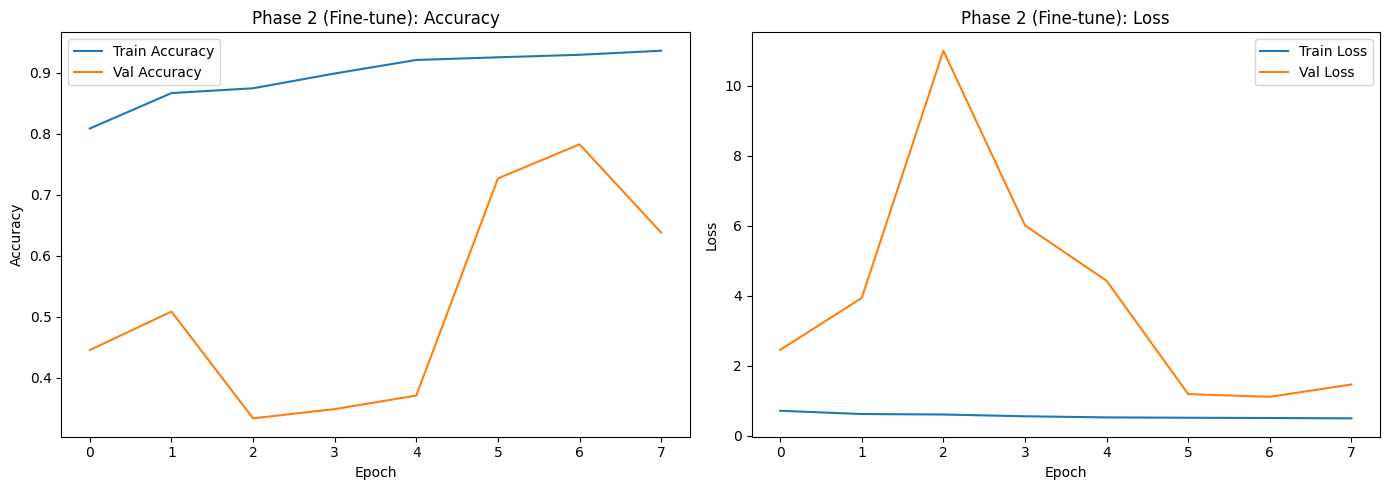

In [ ]:
# Grafica de las curvas de entrenamiento de la Fase 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(hist2.history['accuracy'], label='Train Accuracy')
ax1.plot(hist2.history['val_accuracy'], label='Val Accuracy')
ax1.set_title('Phase 2 (Fine-tune): Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()

ax2.plot(hist2.history['loss'], label='Train Loss')
ax2.plot(hist2.history['val_loss'], label='Val Loss')
ax2.set_title('Phase 2 (Fine-tune): Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()
plt.show()

## Guardar modelo, particiones y registro

In [ ]:
# Guardar el modelo entrenado
model_path = '../modelos/CNN1.keras'
model.save(model_path)
print(f"Model saved to {model_path}")

Model saved to CNN1.keras


In [ ]:
# Guardar los conjuntos de entrenamiento, validación y prueba en carpetas separadas
base_dir = '../datos/splits/CNN1_legado'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'validation')
test_dir = os.path.join(base_dir, 'test')

for d in [train_dir, val_dir, test_dir]:
    os.makedirs(d, exist_ok=True)

def save_split(images, labels, target_dir):
    for i, (img_arr, lbl) in enumerate(zip(images, labels)):
        class_dir = os.path.join(target_dir, str(lbl))
        os.makedirs(class_dir, exist_ok=True)
        img = Image.fromarray(img_arr.astype(np.uint8))
        img.save(os.path.join(class_dir, f'image_{i}.png'))

save_split(x_train, y_train, train_dir)
save_split(x_val, y_val, val_dir)
#save_split(x_test, y_test, test_dir)
print(f"Splits saved to {base_dir}/")
print(f"  Train: {len(os.listdir(os.path.join(train_dir, '0'))) if os.path.exists(os.path.join(train_dir, '0')) else 0} per class")
print(f"  Val:   {len(os.listdir(os.path.join(val_dir, '0'))) if os.path.exists(os.path.join(val_dir, '0')) else 0} per class")
print(f"  Test:  {len(os.listdir(os.path.join(test_dir, '0'))) if os.path.exists(os.path.join(test_dir, '0')) else 0} per class")

Splits saved to CNN1/
  Train: 1142 per class
  Val:   286 per class
  Test:  0 per class


In [ ]:
# Registrar la información del experimento en un archivo CSV
new_exp = {
    'ID_Exp': f"EXP{len(df_log)}",
    'Hash': hash_input,
    'Languages': LANGUAGES,
    'Model': USED_MODEL,
    'Audio_Length': AUDIO_LENGTH,
    'Image_Amount': image_amount,
    'Parameters': parameters,
    #'Results': f"Accuracy: {accuracy:.4f} Recall: {recall:.4f} Precision: {precision:.4f} F1: {f1:.4f}",
    'Split_Seed': SPLIT_SEED,
    'hasSilence': HAS_SILENCE,
    'Audio_Folders_Used': FOLDER_PATH_LIST,
    'Notes': ''
}

df_log = pd.concat([df_log, pd.DataFrame([new_exp])], ignore_index=True)
df_log.to_csv(CSV_LOG_PATH, index=False)
print(f"Experiment logged to {CSV_LOG_PATH}")
display(df_log.tail())

Experiment logged to log.csv


,ID_Exp,Hash,Languages,Model,Audio_Length,Image_Amount,Parameters,Results,Notes,Split_Seed,hasSilence,Audio_Folders_Used
6,EXP6,8a9d31cc211e5b85bbba119a471b3060,"['maya', 'nahuatl', 'zapoteco']",ResNet152V2,3.0,"{'maya': 1165, 'nahuatl': 1165, 'zapoteco': 1165}","{'batch_size': 10, 'frequency': 16000, 'learni...",Accuracy: 0.8590 Recall: 0.8590 Precision: 0.8...,NaN,4.0,False,"['Audios_Usar3s/Maya', 'Audios_Usar3s/Nahuatl'..."
7,EXP7,b10488adb5396bee327152a82620411c,"['maya', 'nahuatl', 'zapoteco']",MobileNetV2,5.0,"{'maya': 1731, 'nahuatl': 1731, 'zapoteco': 1731}","{'batch_size': 32, 'frequency': 16000, 'learni...",Accuracy: 0.6881 Recall: 0.6881 Precision: 0.7...,NaN,4.0,False,"['Audios_Usar5s v2/Maya', 'Audios_Usar5s v2/Na..."
8,EXP8,0ffe3bc40cbd3761561b16a6f8973b55,"['maya', 'nahuatl', 'zapoteco']",MobileNetV2,5.0,"{'maya': 1731, 'nahuatl': 1731, 'zapoteco': 1731}","{'batch_size': 32, 'frequency': 16000, 'learni...",Accuracy: 0.7240 Recall: 0.7240 Precision: 0.7...,NaN,4.0,False,"['Audios_Usar5s v2/Maya', 'Audios_Usar5s v2/Na..."
9,EXP9,0ffe3bc40cbd3761561b16a6f8973b55,"['maya', 'nahuatl', 'zapoteco']",MobileNetV2,5.0,"{'maya': 1428, 'nahuatl': 1428, 'zapoteco': 1428}","{'batch_size': 32, 'frequency': 16000, 'learni...",NaN,NaN,4.0,False,"['Audios_Usar5s v2/Maya', 'Audios_Usar5s v2/Na..."
10,EXP10,0ffe3bc40cbd3761561b16a6f8973b55,"[maya, nahuatl, zapoteco]",MobileNetV2,5.0,"{'maya': 1428, 'nahuatl': 1428, 'zapoteco': 1428}","{'batch_size': 32, 'frequency': 16000, 'learni...",NaN,,4.0,False,"[Audios_Usar5s v2/Maya, Audios_Usar5s v2/Nahua..."
